# Validación para regresión

Usar los siguientes datasets para regresión:

- California Housing
- Diabetes Regression
- Auto MPG
- Bike Sharing

Y para cada dataset aplicar los siguientes modelos:

- Regresión Lineal
- Ridge Regression
- KNN Regressor
- Decision Tree Regressor
- Random Forest Regressor
- SVR

Metricas para cada modelo de regresión:

- MSE
- RMSE
- MAE
- R2
- MAPE
- MSLE

Y a cada modelo se le aplicaran los cinco metodos de validación siguientes:

1. Hold-Out / Train-Test Split:
	Se divide el conjunto de datos una sola vez. El modelo se entrena con una parte y se evalúa con la otra.
2. K-Fold Cross Validation:
	El dataset se divide en K partes. En cada iteración, una parte se usa para validar y las demás para entrenar. Al final se promedian los resultados.
	Usado en base de datos medianas.
3. Stratified K-Fold:
	Variante de K-Fold que conserva aproximadamente la proporción de clases en cada partición de clases en cada partición.
	Busca que en cada K (grupo) estén lo mas balanceados respecto a clases.
4. Leave-One-Out:
	Caso extremo de K-Fold cada observación se usa una vez como prueba y el resto como entrenamiento.
5. Bootstrap:
	Se generan múltiples muestras con remplazo. Algunos registros se repiten y otros quedan fuera. Permitiendo estimar el rendimiento del modelo.



In [1]:
"""
Importar modelos de regresión, metricas y metodos de validación
"""

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, LeaveOneOut

# Utilidades para escalar los datos y clonar los modelos en cada validación
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor

#### Consideraciones

- **Escalado:** Regresión Lineal, Ridge, KNN y SVR se entrenan dentro de un `Pipeline` con `StandardScaler`, de modo que el escalado se ajusta solo con los datos de entrenamiento de cada partición (sin fuga de información). Los árboles y el Random Forest no lo necesitan.
- **SVR:** además se escala la variable objetivo (`TransformedTargetRegressor`), porque con objetivos de gran magnitud (p. ej. `cnt` o `MedHouseVal`) el SVR con parámetros por defecto rinde muy mal. Las métricas se calculan siempre en la escala original.
- **Stratified K-Fold en regresión:** como no hay clases, la variable objetivo se divide en 10 intervalos por cuantiles y se estratifica sobre esos intervalos.
- **Leave-One-Out:** entrena un modelo por observación, por lo que es inviable en datasets grandes. Con más de 500 observaciones (California Housing y Bike Sharing) se aplica sobre una muestra aleatoria de 500. Las predicciones de todas las iteraciones se juntan y las métricas se calculan una sola vez (con una sola observación por iteración, el R2 no está definido).
- **Bootstrap:** en cada iteración se entrena con una muestra con reemplazo y se evalúa con las observaciones que quedaron fuera (out-of-bag). Se promedian las métricas de todas las iteraciones.
- **Gráficas de regresión (30 por dataset):** para cada modelo y método se grafican valores reales vs predicciones. Hold-Out usa el 20 % de prueba; K-Fold y Stratified K-Fold usan la predicción de cada observación cuando estuvo en el fold de prueba; Leave-One-Out usa las predicciones individuales; Bootstrap usa la predicción promedio de cada observación en las iteraciones donde quedó fuera. El R2 de cada gráfica se calcula sobre esas predicciones juntas, por lo que puede diferir ligeramente del R2 de la tabla (promedio por fold o por iteración).
- **Hold-Out:** 80 % entrenamiento y 20 % prueba. **K-Fold y Stratified K-Fold:** K = 5.

In [2]:
"""
Importar y cargar datasets
"""

import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing, load_diabetes
from ucimlrepo import fetch_ucirepo

# California Housing (variable objetivo: MedHouseVal)
california = fetch_california_housing(as_frame=True)
df_california = california.frame

# Diabetes Regression (variable objetivo: target)
diabetes = load_diabetes(as_frame=True)
df_diabetes = diabetes.frame

# Auto MPG (variable objetivo: mpg)
auto_mpg = fetch_ucirepo(id=9)
df_auto = pd.concat([auto_mpg.data.features, auto_mpg.data.targets], axis=1)

# Bike Sharing (variable objetivo: cnt)
bike = fetch_ucirepo(id=275)
df_bike = pd.concat([bike.data.features, bike.data.targets], axis=1)

In [3]:
"""
Preprocesar los datasets: quitar columnas que no aportan, eliminar nulos y convertir variables categóricas a numéricas
"""

def preparar_dataset(df, columna_objetivo, columnas_ignorar=None):
    """
    Devuelve X (características numéricas) y y (variable objetivo numérica).
    """
    # 1. Hacer una copia para no alterar el dataset original
    datos = df.copy()

    # 2. Eliminar columnas que no aportan (IDs, fechas) o que filtran la respuesta
    if columnas_ignorar:
        columnas_existentes = [col for col in columnas_ignorar if col in datos.columns]
        datos = datos.drop(columns=columnas_existentes)

    # 3. Eliminar filas con valores nulos
    datos = datos.dropna()

    # 4. Separar la variable objetivo y forzarla a numérica
    y = pd.to_numeric(datos[columna_objetivo], errors='coerce')
    X = datos.drop(columns=[columna_objetivo])

    # 5. Convertir variables categóricas (texto) a numéricas
    X = pd.get_dummies(X, drop_first=True, dtype=float)

    # 6. Eliminar filas cuyo objetivo no se pudo convertir
    mascara = y.notna()
    X = X.loc[mascara].reset_index(drop=True)
    y = y.loc[mascara].reset_index(drop=True)

    return X, y

datasets = {
    "California Housing": preparar_dataset(df_california, 'MedHouseVal'),
    "Diabetes Regression": preparar_dataset(df_diabetes, 'target'),
    "Auto MPG": preparar_dataset(df_auto, 'mpg'),
    # casual y registered suman exactamente cnt, por lo que se eliminan para evitar fuga de información
    "Bike Sharing": preparar_dataset(df_bike, 'cnt', columnas_ignorar=['instant', 'dteday', 'casual', 'registered']),
}

# Resumen de los datasets ya trabajados
resumen = pd.DataFrame({
    nombre: {
        "Observaciones": X.shape[0],
        "Características": X.shape[1],
        "Objetivo mínimo": y.min(),
        "Objetivo máximo": y.max(),
        "Objetivo media": y.mean(),
    }
    for nombre, (X, y) in datasets.items()
}).T
print(resumen)

                     Observaciones  Características  Objetivo mínimo  \
California Housing         20640.0              8.0          0.14999   
Diabetes Regression          442.0             10.0         25.00000   
Auto MPG                     392.0              7.0          9.00000   
Bike Sharing               17379.0             12.0          1.00000   

                     Objetivo máximo  Objetivo media  
California Housing           5.00001        2.068558  
Diabetes Regression        346.00000      152.133484  
Auto MPG                    46.60000       23.445918  
Bike Sharing               977.00000      189.463088  


In [4]:
"""
Funcion para crear los modelos de regresión
"""

def crear_modelos():
    """
    Devuelve un diccionario con los 6 modelos de regresión.
    Los modelos sensibles a la escala se envuelven en un Pipeline con StandardScaler.
    """
    return {
        "Regresión Lineal": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "KNN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5, n_jobs=-1)),
        "Decision Tree": DecisionTreeRegressor(random_state=42),
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
        # SVR: se escala también la variable objetivo
        "SVR": TransformedTargetRegressor(
            regressor=make_pipeline(StandardScaler(), SVR()),
            transformer=StandardScaler()
        ),
    }

In [5]:
"""
Funcion para calcular las metricas de regresión: MSE, RMSE, MAE, R2, MAPE y MSLE
"""

def calcular_metricas(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_real, y_pred)
    r2 = r2_score(y_real, y_pred) if len(y_real) > 1 else np.nan

    # Evitar división por cero en MAPE
    y_real_safe = np.where(y_real == 0, 1e-10, y_real)
    mape = np.mean(np.abs((y_real - y_pred) / y_real_safe)) * 100

    # MSLE real (usando logaritmos); se recortan negativos porque log1p no los admite
    msle = np.mean(np.square(np.log1p(np.maximum(y_real, 0)) - np.log1p(np.maximum(y_pred, 0))))

    return {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
        "MAPE": mape,
        "MSLE": msle
    }

def promediar_metricas(lista_metricas):
    """
    Promedia las metricas obtenidas en cada iteración de la validación.
    """
    return pd.DataFrame(lista_metricas).mean().to_dict()

In [6]:
"""
Funciones para los cinco metodos de validación
Cada función devuelve: las metricas, los valores reales y las predicciones (para graficar la regresión)
"""

# 1. Hold-Out / Train-Test Split
def validacion_holdout(modelo, X, y, test_size=0.2, random_state=42):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    m = clone(modelo)
    m.fit(X_train, y_train)
    predicciones = m.predict(X_test)
    return calcular_metricas(y_test, predicciones), y_test.to_numpy(), predicciones


# 2. K-Fold Cross Validation
def validacion_kfold(modelo, X, y, k=5, random_state=42):
    cv = KFold(n_splits=k, shuffle=True, random_state=random_state)
    resultados = []
    predicciones = np.zeros(len(y))
    for idx_train, idx_test in cv.split(X):
        m = clone(modelo)
        m.fit(X.iloc[idx_train], y.iloc[idx_train])
        pred_fold = m.predict(X.iloc[idx_test])
        predicciones[idx_test] = pred_fold
        resultados.append(calcular_metricas(y.iloc[idx_test], pred_fold))
    # Metricas: promedio de los K folds. Predicciones: cada observación predicha cuando estuvo en prueba
    return promediar_metricas(resultados), y.to_numpy(), predicciones


# 3. Stratified K-Fold
def validacion_stratified_kfold(modelo, X, y, k=5, bins=10, random_state=42):
    # En regresión no hay clases: se discretiza el objetivo en intervalos por cuantiles
    y_estratos = pd.qcut(y, q=bins, labels=False, duplicates='drop')
    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=random_state)
    resultados = []
    predicciones = np.zeros(len(y))
    for idx_train, idx_test in cv.split(X, y_estratos):
        m = clone(modelo)
        m.fit(X.iloc[idx_train], y.iloc[idx_train])
        pred_fold = m.predict(X.iloc[idx_test])
        predicciones[idx_test] = pred_fold
        resultados.append(calcular_metricas(y.iloc[idx_test], pred_fold))
    return promediar_metricas(resultados), y.to_numpy(), predicciones


# 4. Leave-One-Out
def validacion_leave_one_out(modelo, X, y, max_muestras=500, random_state=42):
    # Si el dataset es grande se trabaja con una muestra aleatoria para que el tiempo sea razonable
    if len(X) > max_muestras:
        idx = np.random.RandomState(random_state).choice(len(X), max_muestras, replace=False)
        X = X.iloc[idx].reset_index(drop=True)
        y = y.iloc[idx].reset_index(drop=True)

    predicciones = np.zeros(len(y))
    for idx_train, idx_test in LeaveOneOut().split(X):
        m = clone(modelo)
        m.fit(X.iloc[idx_train], y.iloc[idx_train])
        predicciones[idx_test] = m.predict(X.iloc[idx_test])

    # Las metricas se calculan con todas las predicciones juntas
    return calcular_metricas(y, predicciones), y.to_numpy(), predicciones


# 5. Bootstrap
def validacion_bootstrap(modelo, X, y, n_iteraciones=30, random_state=42):
    rng = np.random.RandomState(random_state)
    n = len(X)
    resultados = []
    suma_pred = np.zeros(n)
    conteo = np.zeros(n)
    for _ in range(n_iteraciones):
        # Muestra con reemplazo para entrenar; lo que no se eligió (out-of-bag) sirve para evaluar
        idx_train = rng.choice(n, size=n, replace=True)
        idx_test = np.setdiff1d(np.arange(n), idx_train)
        if len(idx_test) == 0:
            continue
        m = clone(modelo)
        m.fit(X.iloc[idx_train], y.iloc[idx_train])
        pred = m.predict(X.iloc[idx_test])
        suma_pred[idx_test] += pred
        conteo[idx_test] += 1
        resultados.append(calcular_metricas(y.iloc[idx_test], pred))

    # Para graficar: predicción promedio de cada observación en las iteraciones donde quedó fuera
    vistas = conteo > 0
    predicciones = suma_pred[vistas] / conteo[vistas]
    return promediar_metricas(resultados), y.to_numpy()[vistas], predicciones

In [7]:
"""
Funcion para aplicar los 6 modelos con los 5 metodos de validación a un dataset
"""

import time

def evaluar_validaciones(X, y, nombre_dataset, k=5, n_bootstrap=30, max_loo=500):
    """
    Devuelve:
    - un DataFrame con las metricas de cada modelo y cada metodo de validación
    - un diccionario {(modelo, metodo): (y_real, y_pred)} para graficar la regresión
    """
    metodos = {
        "Hold-Out": lambda m: validacion_holdout(m, X, y),
        "K-Fold": lambda m: validacion_kfold(m, X, y, k=k),
        "Stratified K-Fold": lambda m: validacion_stratified_kfold(m, X, y, k=k),
        "Leave-One-Out": lambda m: validacion_leave_one_out(m, X, y, max_muestras=max_loo),
        "Bootstrap": lambda m: validacion_bootstrap(m, X, y, n_iteraciones=n_bootstrap),
    }

    filas = []
    predicciones = {}
    for nombre_modelo, modelo in crear_modelos().items():
        for nombre_metodo, aplicar in metodos.items():
            inicio = time.time()
            metricas, y_real, y_pred = aplicar(modelo)
            print(f"{nombre_dataset} | {nombre_modelo} | {nombre_metodo} ({time.time() - inicio:.1f} s)")
            filas.append({
                "Dataset": nombre_dataset,
                "Modelo": nombre_modelo,
                "Validación": nombre_metodo,
                **metricas
            })
            predicciones[(nombre_modelo, nombre_metodo)] = (y_real, y_pred)

    return pd.DataFrame(filas), predicciones

In [8]:
"""
Funcion para mostrar graficamente la comparación de modelos y metodos de validación (MSE, RMSE, MAE, R2, MAPE y MSLE)
"""
import matplotlib.pyplot as plt

def graficar_comparacion(df_resultados, nombre_dataset):
    """
    Toma el DataFrame de resultados y genera 6 subgráficos (Metricas: MSE, RMSE, MAE, R2, MAPE y MSLE)
    con barras agrupadas por modelo y coloreadas por método de validación.
    """
    modelos = df_resultados['Modelo'].unique()
    metodos = df_resultados['Validación'].unique()

    fig, axes = plt.subplots(3, 2, figsize=(10, 10))
    fig.suptitle(f'Comparación de Modelos y Métodos de Validación: {nombre_dataset}', fontsize=16, y=1.02)

    # axes es una matriz de 2x3, se aplana para poder recorrerla con un solo ciclo
    for ax, metrica in zip(axes.flatten(), ['MSE', 'RMSE', 'MAE', 'R2', 'MAPE', 'MSLE']):
        tabla = df_resultados.pivot(index='Modelo', columns='Validación', values=metrica)
        tabla = tabla.loc[modelos, metodos]
        tabla.plot(kind='bar', ax=ax, width=0.85)

        ax.set_title(metrica)
        ax.set_xlabel('Modelo')
        ax.set_ylabel(metrica)
        ax.tick_params(axis='x', rotation=30)
        ax.legend(title='Validación', fontsize=8)

    plt.tight_layout()
    plt.show()

In [9]:
"""
Funcion para mostrar graficamente que tan bien predice cada modelo con cada metodo de validación (valores reales vs predicciones)
"""

def graficar_regresion(predicciones, nombre_dataset):
    """
    Genera una cuadricula de 6 modelos (filas) x 5 metodos de validación (columnas) = 30 graficas.
    Mientras más cerca estén los puntos de la línea roja, mejor predice el modelo.
    """
    modelos = list(dict.fromkeys(m for m, _ in predicciones))
    metodos = list(dict.fromkeys(v for _, v in predicciones))

    fig, axes = plt.subplots(len(modelos), len(metodos), figsize=(5 * len(metodos), 4 * len(modelos)))
    fig.suptitle(f'Regresión: Valores Reales vs Predicciones - {nombre_dataset}', fontsize=18, y=1.0)

    for i, nombre_modelo in enumerate(modelos):
        for j, nombre_metodo in enumerate(metodos):
            ax = axes[i, j]
            y_real, y_pred = predicciones[(nombre_modelo, nombre_metodo)]
            r2 = r2_score(y_real, y_pred)

            ax.scatter(y_real, y_pred, alpha=0.5, s=12)
            ax.plot([y_real.min(), y_real.max()], [y_real.min(), y_real.max()], 'r--', lw=2)
            ax.set_title(f'{nombre_modelo} | {nombre_metodo}\nR2 = {r2:.3f}', fontsize=10)
            ax.set_xlabel('Valores Reales')
            ax.set_ylabel('Predicciones')

    plt.tight_layout()
    plt.show()

#### California Housing

California Housing | Regresión Lineal | Hold-Out (0.0 s)
California Housing | Regresión Lineal | K-Fold (0.0 s)
California Housing | Regresión Lineal | Stratified K-Fold (0.0 s)
California Housing | Regresión Lineal | Leave-One-Out (1.3 s)
California Housing | Regresión Lineal | Bootstrap (0.1 s)
California Housing | Ridge | Hold-Out (0.0 s)
California Housing | Ridge | K-Fold (0.0 s)
California Housing | Ridge | Stratified K-Fold (0.0 s)
California Housing | Ridge | Leave-One-Out (1.4 s)
California Housing | Ridge | Bootstrap (0.1 s)
California Housing | KNN | Hold-Out (0.1 s)
California Housing | KNN | K-Fold (0.5 s)
California Housing | KNN | Stratified K-Fold (0.5 s)
California Housing | KNN | Leave-One-Out (14.3 s)
California Housing | KNN | Bootstrap (1.9 s)
California Housing | Decision Tree | Hold-Out (0.1 s)
California Housing | Decision Tree | K-Fold (0.7 s)
California Housing | Decision Tree | Stratified K-Fold (0.7 s)
California Housing | Decision Tree | Leave-One-Out (2.0 

,Dataset,Modelo,Validación,MSE,RMSE,MAE,R2,MAPE,MSLE
0,California Housing,Regresión Lineal,Hold-Out,0.555892,0.745581,0.533200,0.575788,31.952187,0.052351
1,California Housing,Regresión Lineal,K-Fold,0.530572,0.728251,0.531677,0.601378,31.758763,0.050828
2,California Housing,Regresión Lineal,Stratified K-Fold,0.526832,0.725781,0.531449,0.604315,31.722440,0.050760
3,California Housing,Regresión Lineal,Leave-One-Out,0.439615,0.663035,0.483229,0.675890,28.936541,0.042878
4,California Housing,Regresión Lineal,Bootstrap,1.139116,0.911770,0.532719,0.134437,32.009137,0.050504
5,California Housing,Ridge,Hold-Out,0.555855,0.745557,0.533193,0.575816,31.951174,0.052343
6,California Housing,Ridge,K-Fold,0.530569,0.728249,0.531672,0.601381,31.757911,0.050821
7,California Housing,Ridge,Stratified K-Fold,0.526830,0.725779,0.531445,0.604317,31.721688,0.050754
8,California Housing,Ridge,Leave-One-Out,0.439634,0.663049,0.482923,0.675876,28.839136,0.042666
9,California Housing,Ridge,Bootstrap,1.139106,0.911767,0.532717,0.134445,32.008672,0.050499


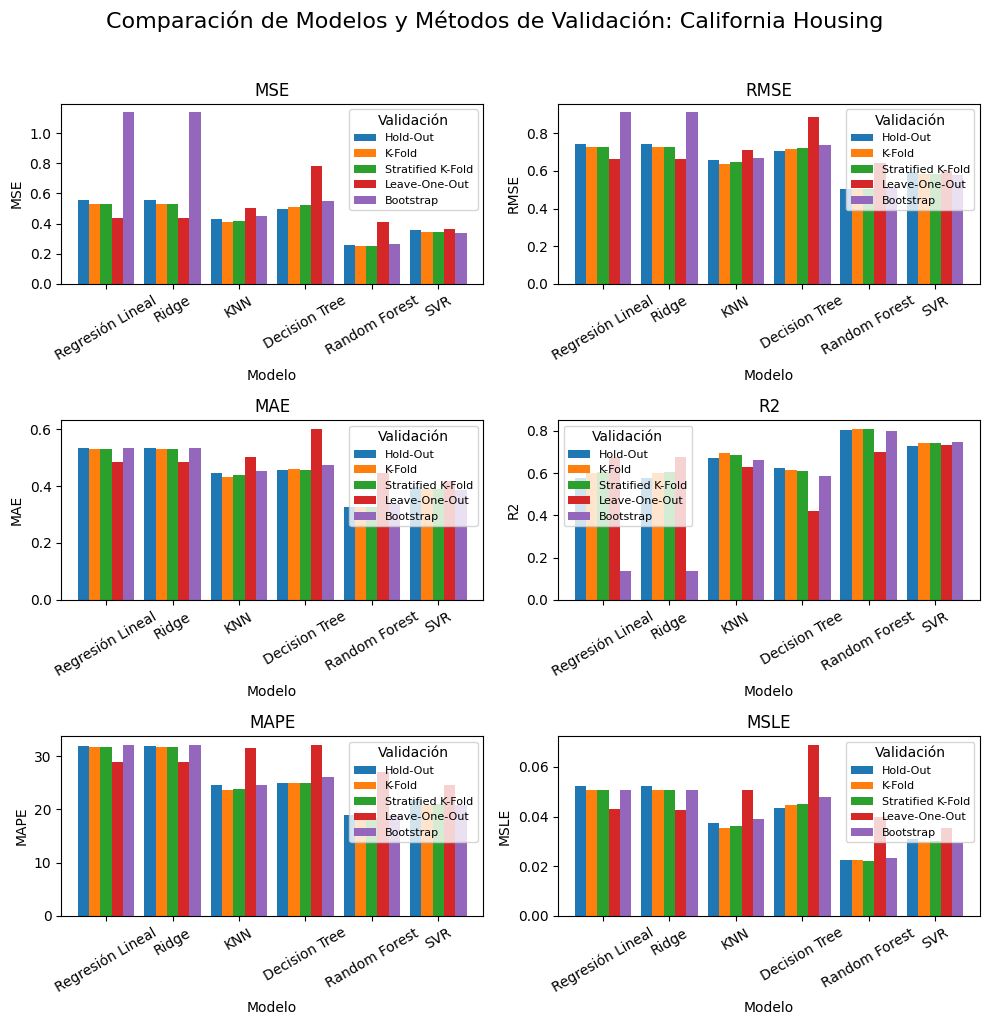

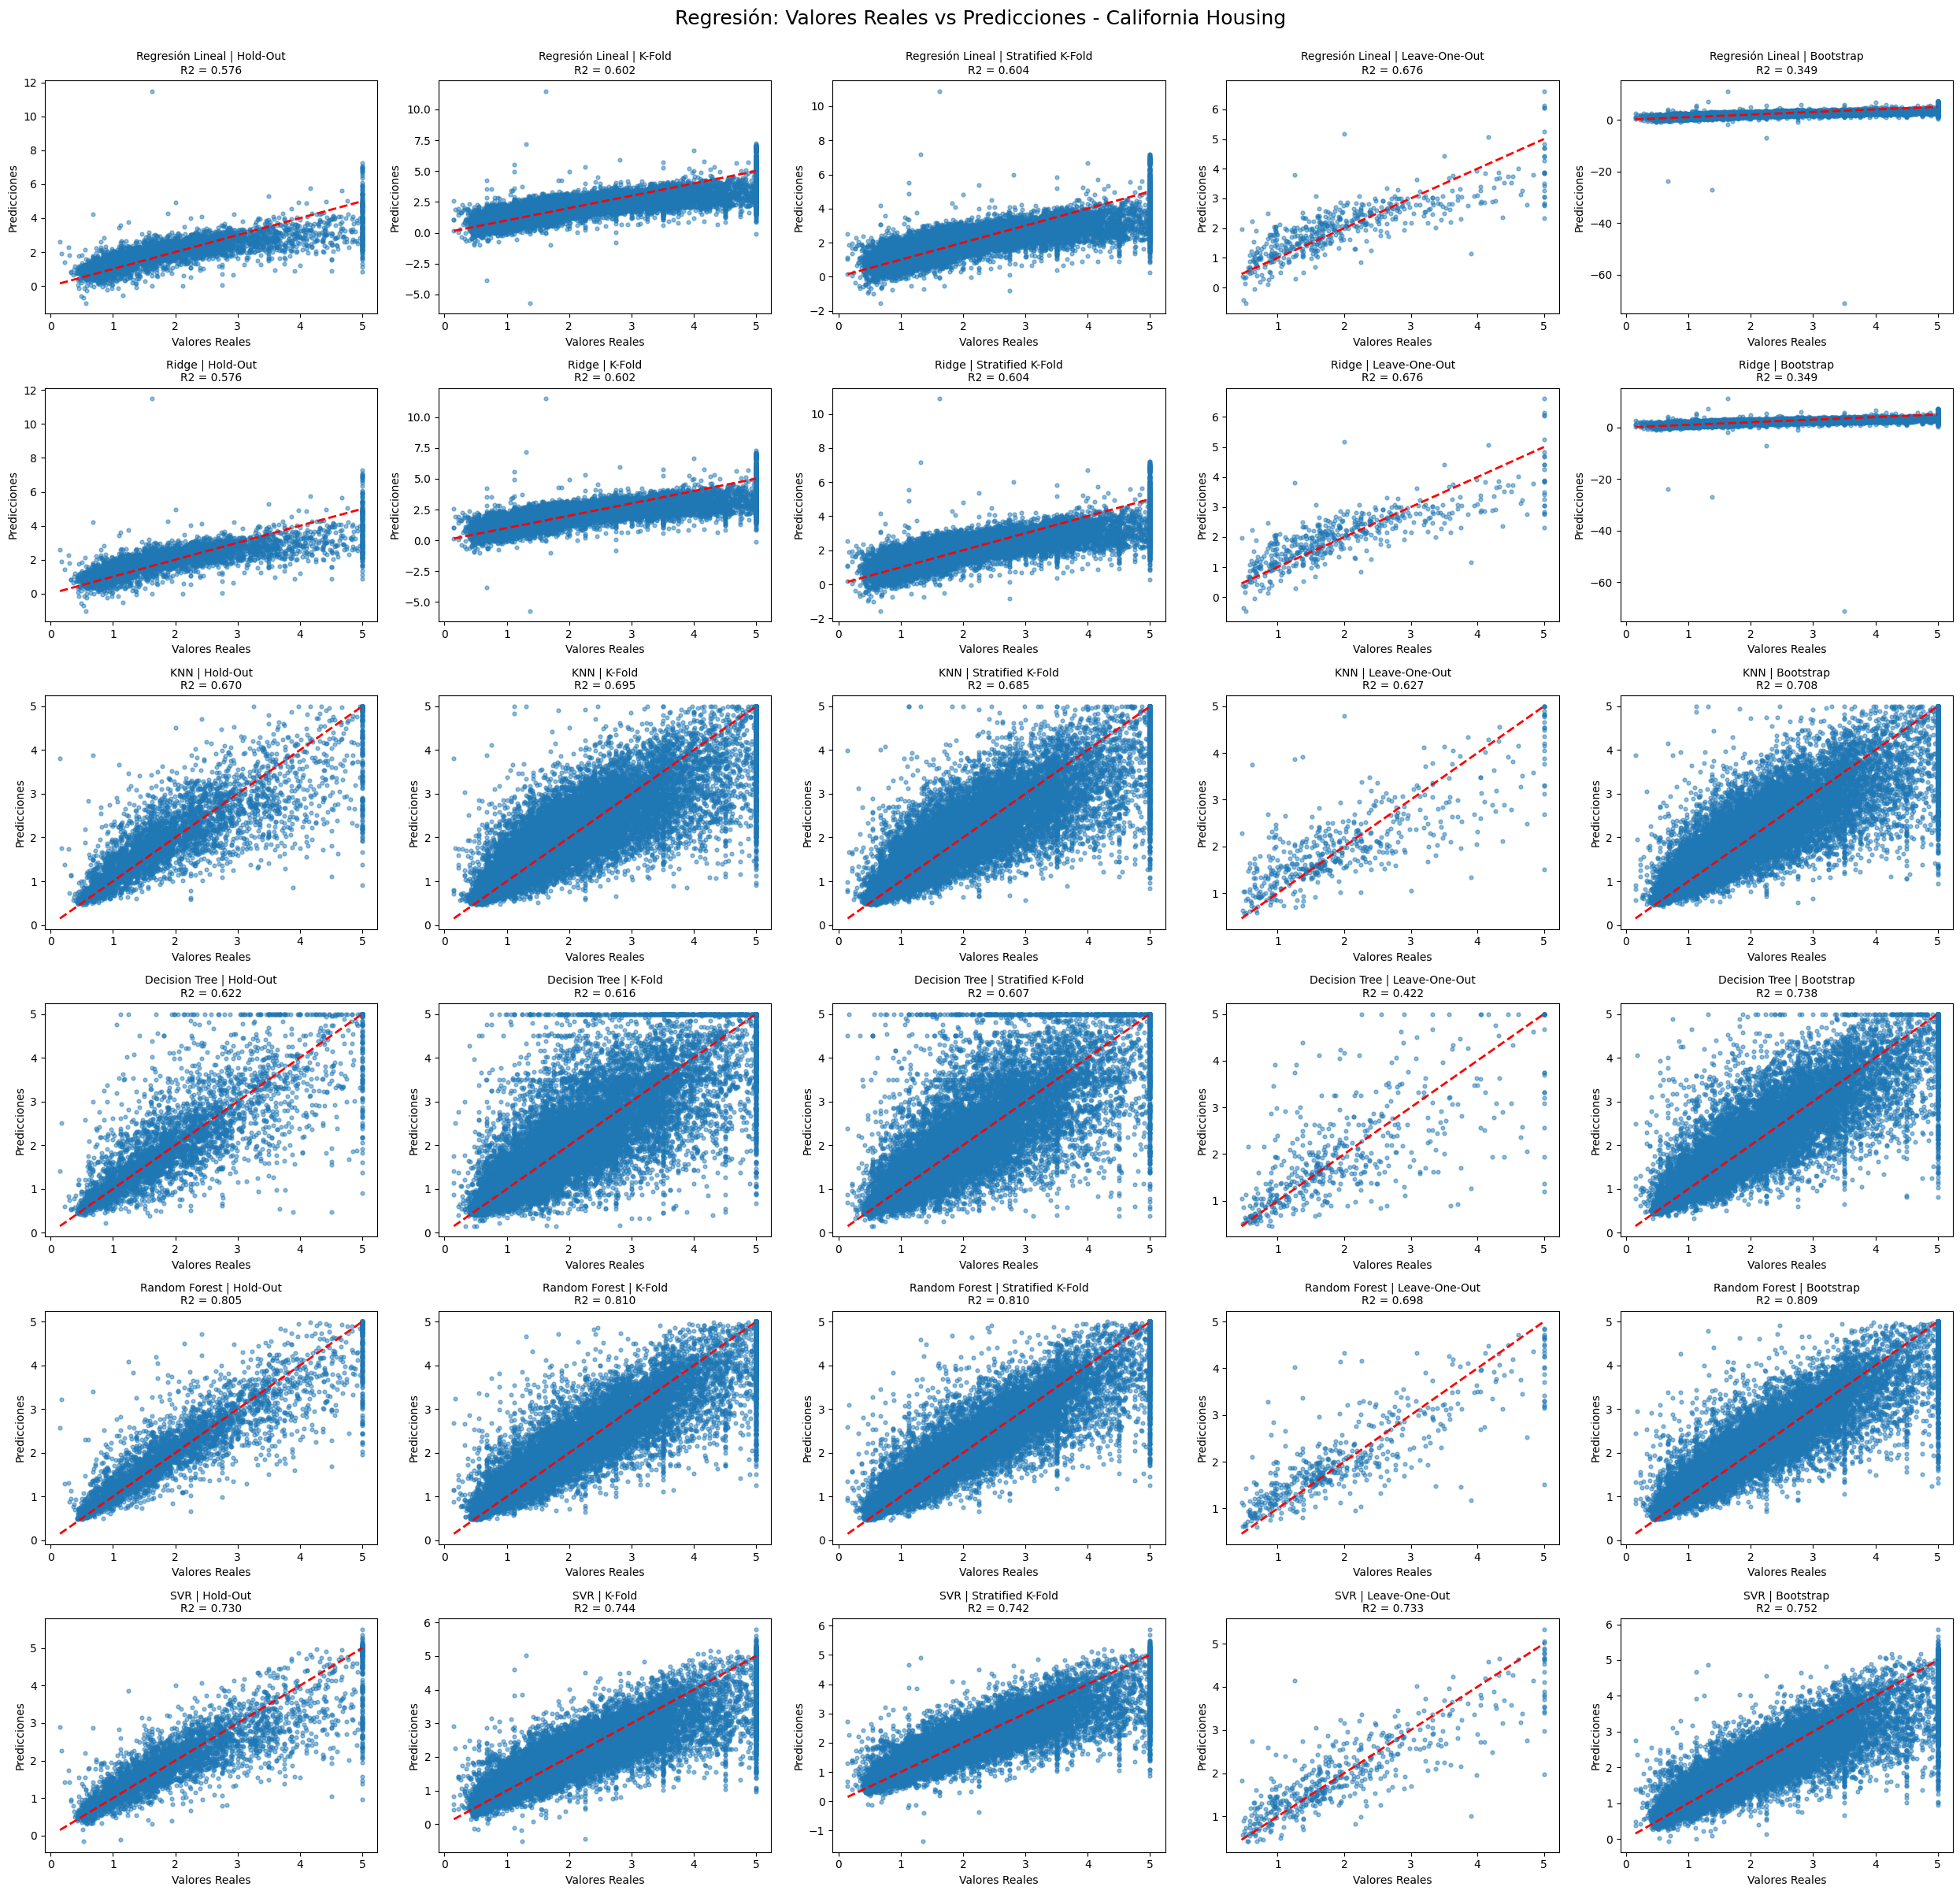

In [10]:
"""
Aplicar los modelos y metodos de validación a California Housing (dataset grande: 10 iteraciones de Bootstrap)
"""
from IPython.display import display

X, y = datasets["California Housing"]
resultados_california, predicciones_california = evaluar_validaciones(X, y, "California Housing", n_bootstrap=10)
display(resultados_california)
graficar_comparacion(resultados_california, "California Housing")
graficar_regresion(predicciones_california, "California Housing")

#### Diabetes Regression

Diabetes Regression | Regresión Lineal | Hold-Out (0.0 s)
Diabetes Regression | Regresión Lineal | K-Fold (0.0 s)
Diabetes Regression | Regresión Lineal | Stratified K-Fold (0.0 s)
Diabetes Regression | Regresión Lineal | Leave-One-Out (1.2 s)
Diabetes Regression | Regresión Lineal | Bootstrap (0.1 s)
Diabetes Regression | Ridge | Hold-Out (0.0 s)
Diabetes Regression | Ridge | K-Fold (0.0 s)
Diabetes Regression | Ridge | Stratified K-Fold (0.0 s)
Diabetes Regression | Ridge | Leave-One-Out (1.2 s)
Diabetes Regression | Ridge | Bootstrap (0.1 s)
Diabetes Regression | KNN | Hold-Out (0.0 s)
Diabetes Regression | KNN | K-Fold (0.1 s)
Diabetes Regression | KNN | Stratified K-Fold (0.1 s)
Diabetes Regression | KNN | Leave-One-Out (12.2 s)
Diabetes Regression | KNN | Bootstrap (0.6 s)
Diabetes Regression | Decision Tree | Hold-Out (0.0 s)
Diabetes Regression | Decision Tree | K-Fold (0.0 s)
Diabetes Regression | Decision Tree | Stratified K-Fold (0.0 s)
Diabetes Regression | Decision Tree | 

,Dataset,Modelo,Validación,MSE,RMSE,MAE,R2,MAPE,MSLE
0,Diabetes Regression,Regresión Lineal,Hold-Out,2900.193628,53.853446,42.794095,0.452603,37.499826,0.176967
1,Diabetes Regression,Regresión Lineal,K-Fold,3015.381694,54.848941,44.269746,0.478470,39.539159,0.179259
2,Diabetes Regression,Regresión Lineal,Stratified K-Fold,2998.583047,54.659036,44.230572,0.490978,39.453426,0.179104
3,Diabetes Regression,Regresión Lineal,Leave-One-Out,3001.752847,54.788255,44.355723,0.493792,39.675864,0.179481
4,Diabetes Regression,Regresión Lineal,Bootstrap,3071.142061,55.385688,44.812503,0.488524,39.765558,0.185606
5,Diabetes Regression,Ridge,Hold-Out,2892.014566,53.777454,42.811999,0.454147,37.448164,0.174983
6,Diabetes Regression,Ridge,K-Fold,3012.577690,54.827054,44.243473,0.479072,39.462603,0.177875
7,Diabetes Regression,Ridge,Stratified K-Fold,2997.600697,54.652147,44.227161,0.491154,39.427507,0.177775
8,Diabetes Regression,Ridge,Leave-One-Out,3000.027956,54.772511,44.336250,0.494083,39.634644,0.178185
9,Diabetes Regression,Ridge,Bootstrap,3065.187046,55.331398,44.762546,0.489501,39.705490,0.182747


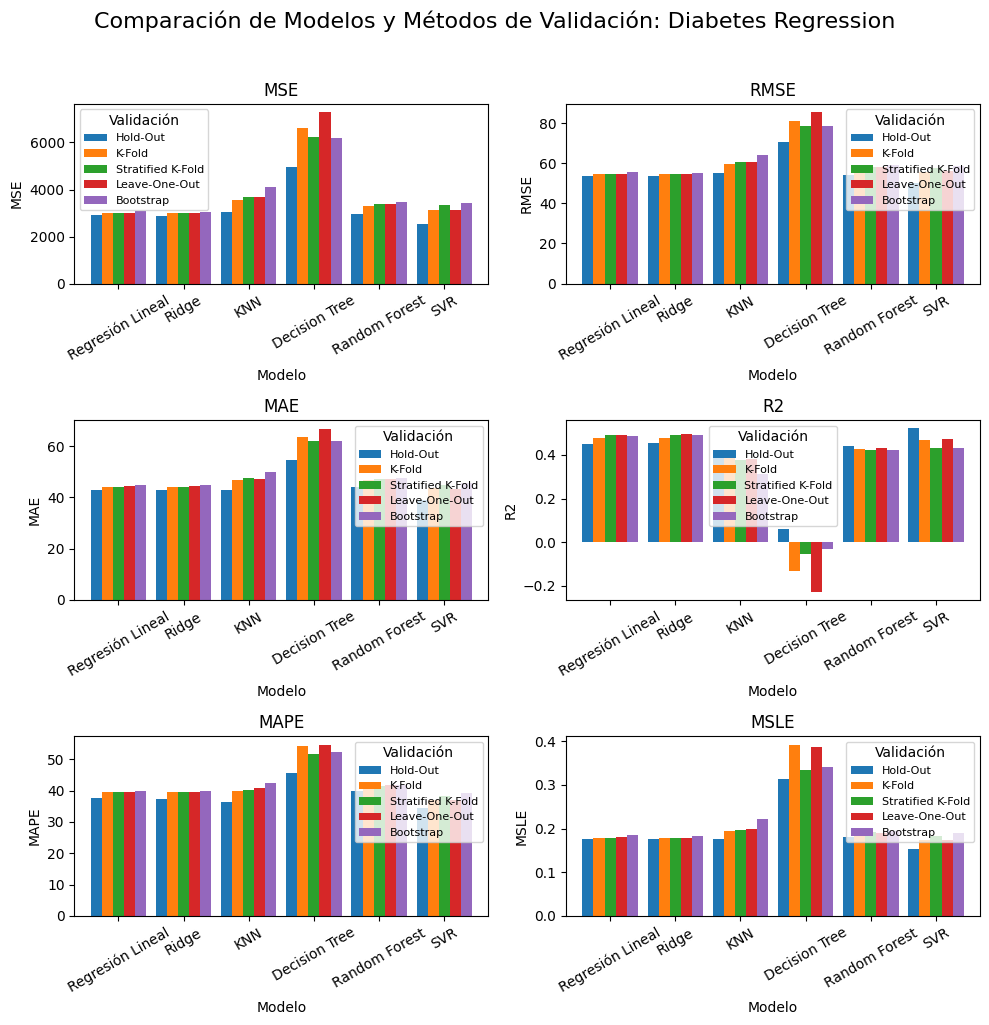

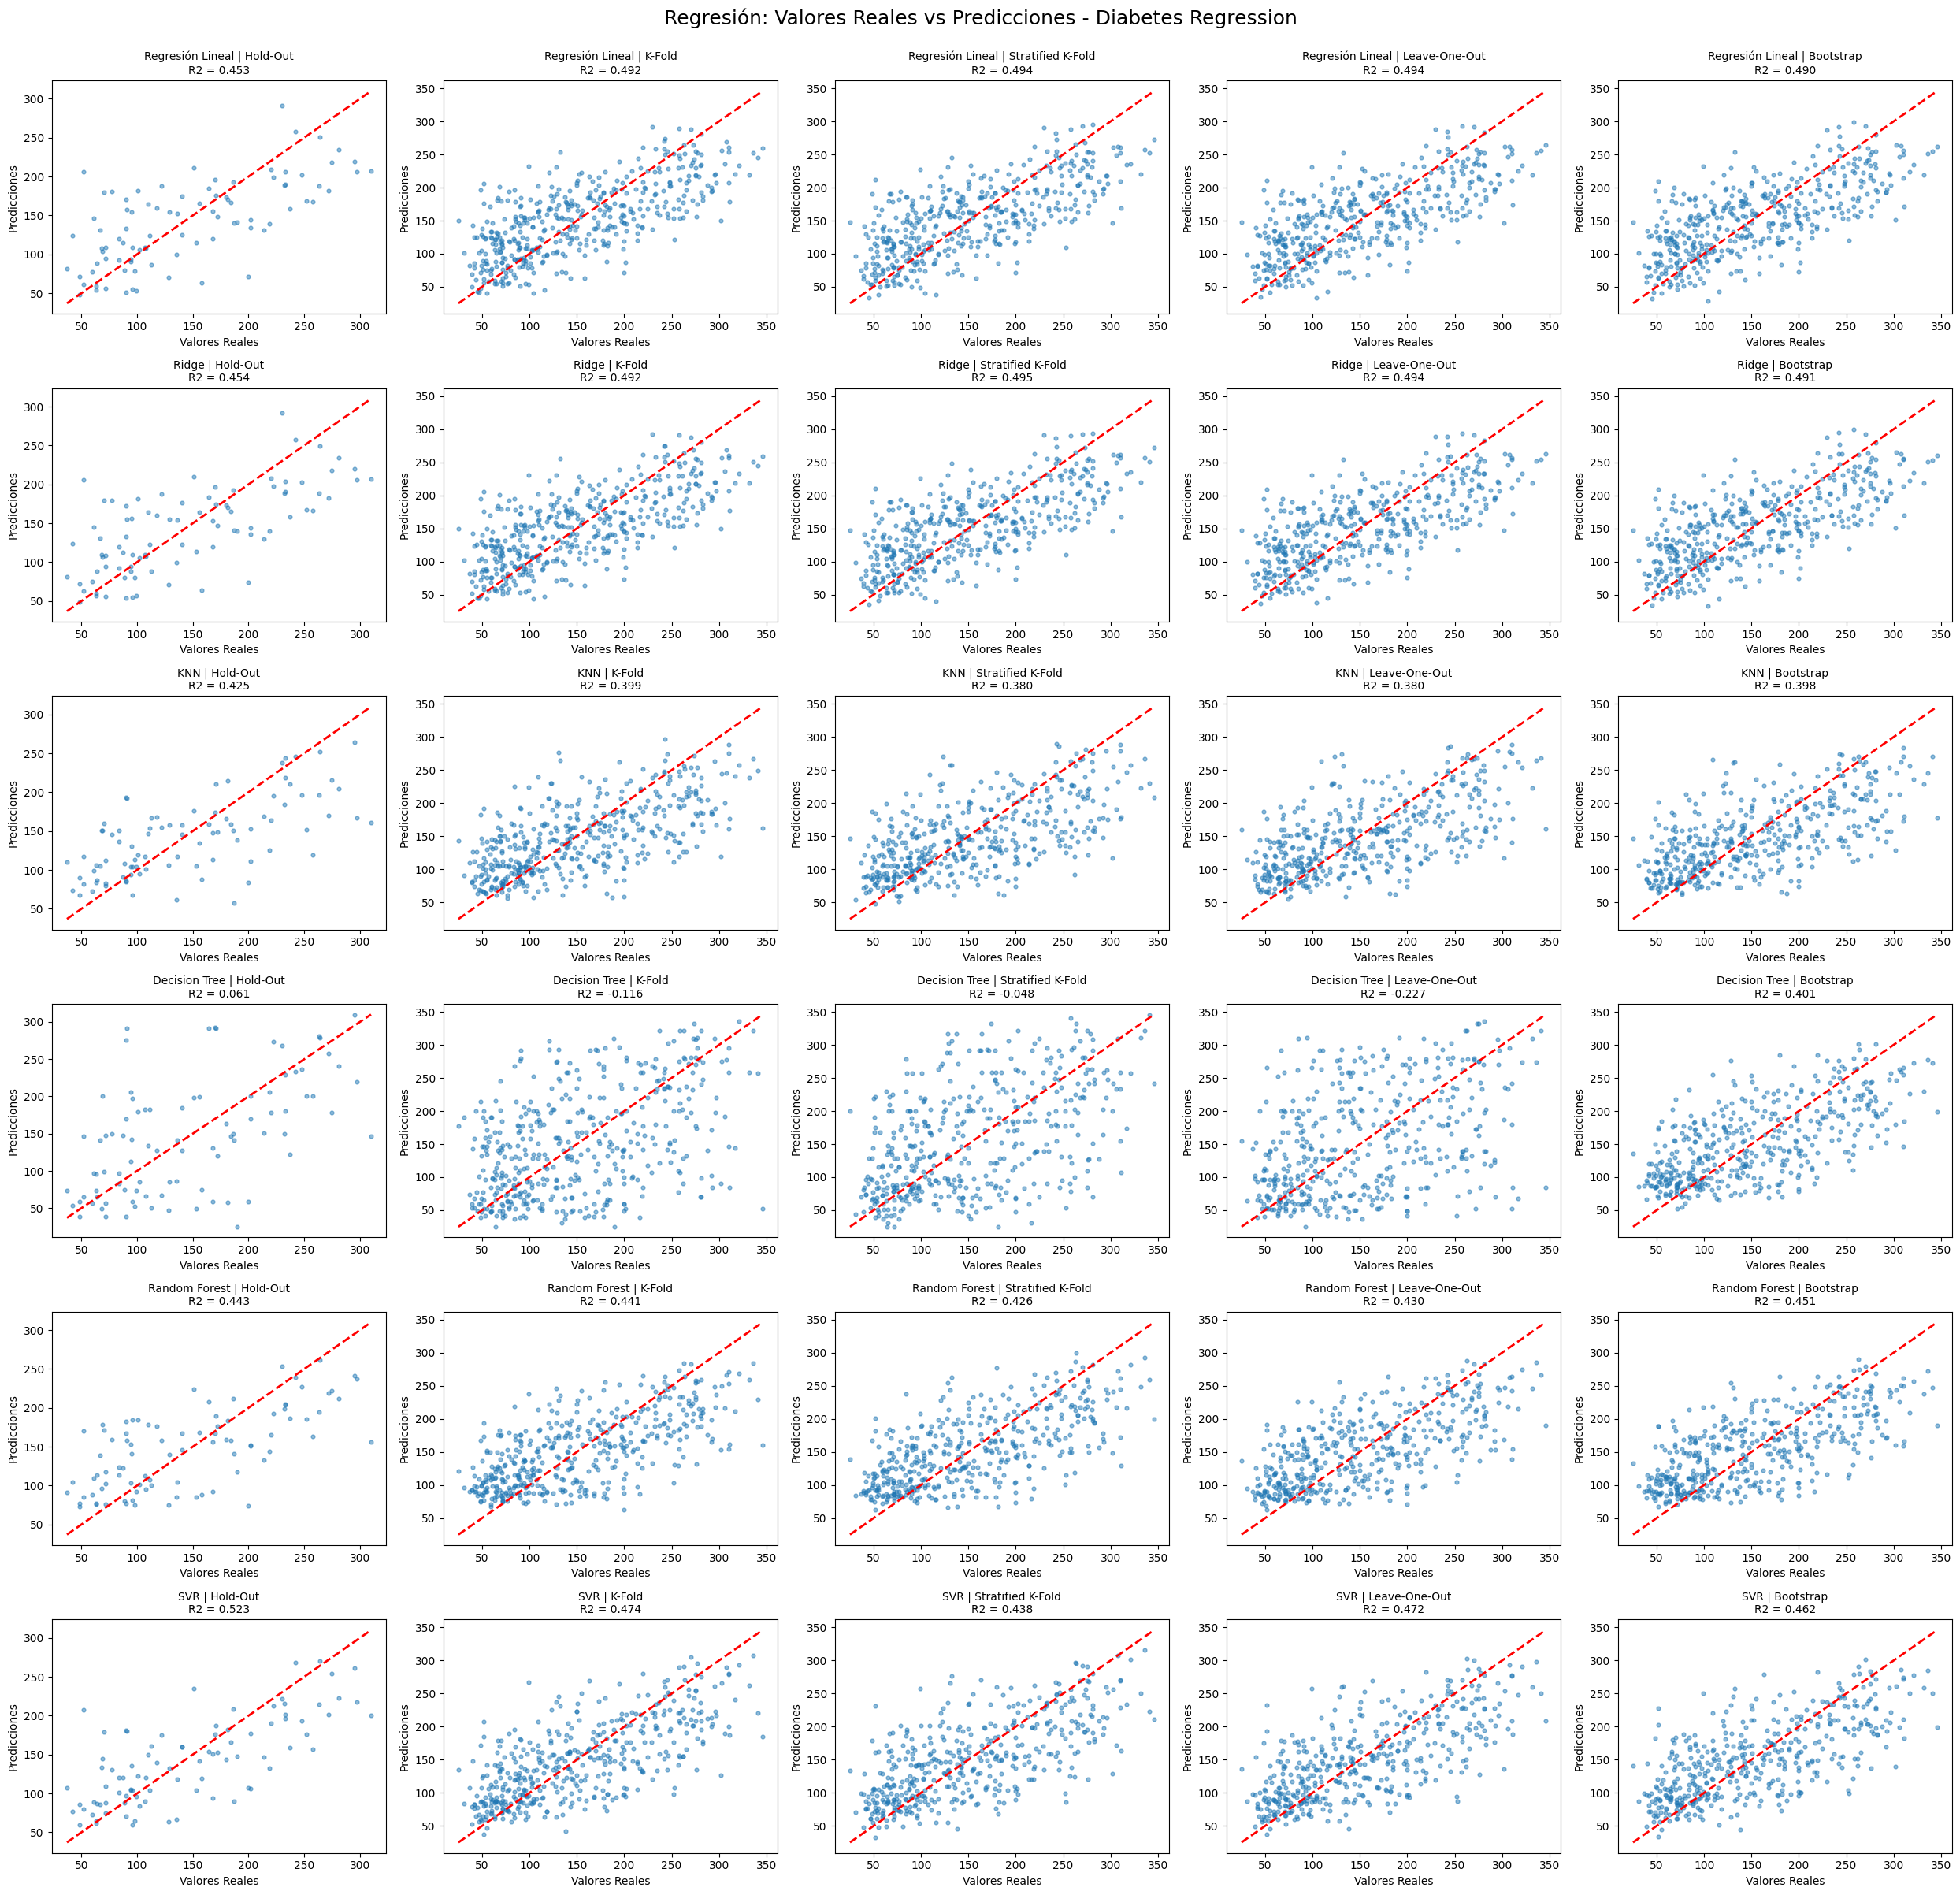

In [11]:
"""
Aplicar los modelos y metodos de validación a Diabetes Regression
"""

X, y = datasets["Diabetes Regression"]
resultados_diabetes, predicciones_diabetes = evaluar_validaciones(X, y, "Diabetes Regression", n_bootstrap=30)
display(resultados_diabetes)
graficar_comparacion(resultados_diabetes, "Diabetes Regression")
graficar_regresion(predicciones_diabetes, "Diabetes Regression")

#### Auto MPG

Auto MPG | Regresión Lineal | Hold-Out (0.0 s)
Auto MPG | Regresión Lineal | K-Fold (0.0 s)
Auto MPG | Regresión Lineal | Stratified K-Fold (0.0 s)
Auto MPG | Regresión Lineal | Leave-One-Out (1.1 s)
Auto MPG | Regresión Lineal | Bootstrap (0.1 s)
Auto MPG | Ridge | Hold-Out (0.0 s)
Auto MPG | Ridge | K-Fold (0.0 s)
Auto MPG | Ridge | Stratified K-Fold (0.0 s)
Auto MPG | Ridge | Leave-One-Out (1.3 s)
Auto MPG | Ridge | Bootstrap (0.1 s)
Auto MPG | KNN | Hold-Out (0.0 s)
Auto MPG | KNN | K-Fold (0.1 s)
Auto MPG | KNN | Stratified K-Fold (0.1 s)
Auto MPG | KNN | Leave-One-Out (11.8 s)
Auto MPG | KNN | Bootstrap (0.6 s)
Auto MPG | Decision Tree | Hold-Out (0.0 s)
Auto MPG | Decision Tree | K-Fold (0.0 s)
Auto MPG | Decision Tree | Stratified K-Fold (0.0 s)
Auto MPG | Decision Tree | Leave-One-Out (1.0 s)
Auto MPG | Decision Tree | Bootstrap (0.1 s)
Auto MPG | Random Forest | Hold-Out (0.1 s)
Auto MPG | Random Forest | K-Fold (0.6 s)
Auto MPG | Random Forest | Stratified K-Fold (0.6 s)
Aut

,Dataset,Modelo,Validación,MSE,RMSE,MAE,R2,MAPE,MSLE
0,Auto MPG,Regresión Lineal,Hold-Out,10.710864,3.272746,2.419780,0.790150,11.789209,0.022957
1,Auto MPG,Regresión Lineal,K-Fold,11.495141,3.375768,2.575829,0.810087,11.934071,0.021919
2,Auto MPG,Regresión Lineal,Stratified K-Fold,11.241486,3.348669,2.536731,0.815140,11.777160,0.021238
3,Auto MPG,Regresión Lineal,Leave-One-Out,11.371126,3.372110,2.556369,0.812860,11.857791,0.021654
4,Auto MPG,Regresión Lineal,Bootstrap,11.590652,3.400814,2.574760,0.804918,11.966980,0.022296
5,Auto MPG,Ridge,Hold-Out,10.767390,3.281370,2.424308,0.789043,11.800382,0.023059
6,Auto MPG,Ridge,K-Fold,11.481231,3.373342,2.569373,0.810320,11.874273,0.021630
7,Auto MPG,Ridge,Stratified K-Fold,11.236965,3.347750,2.532960,0.815244,11.733051,0.020995
8,Auto MPG,Ridge,Leave-One-Out,11.361349,3.370660,2.551414,0.813021,11.810523,0.021449
9,Auto MPG,Ridge,Bootstrap,11.571590,3.397872,2.568588,0.805251,11.913662,0.022007


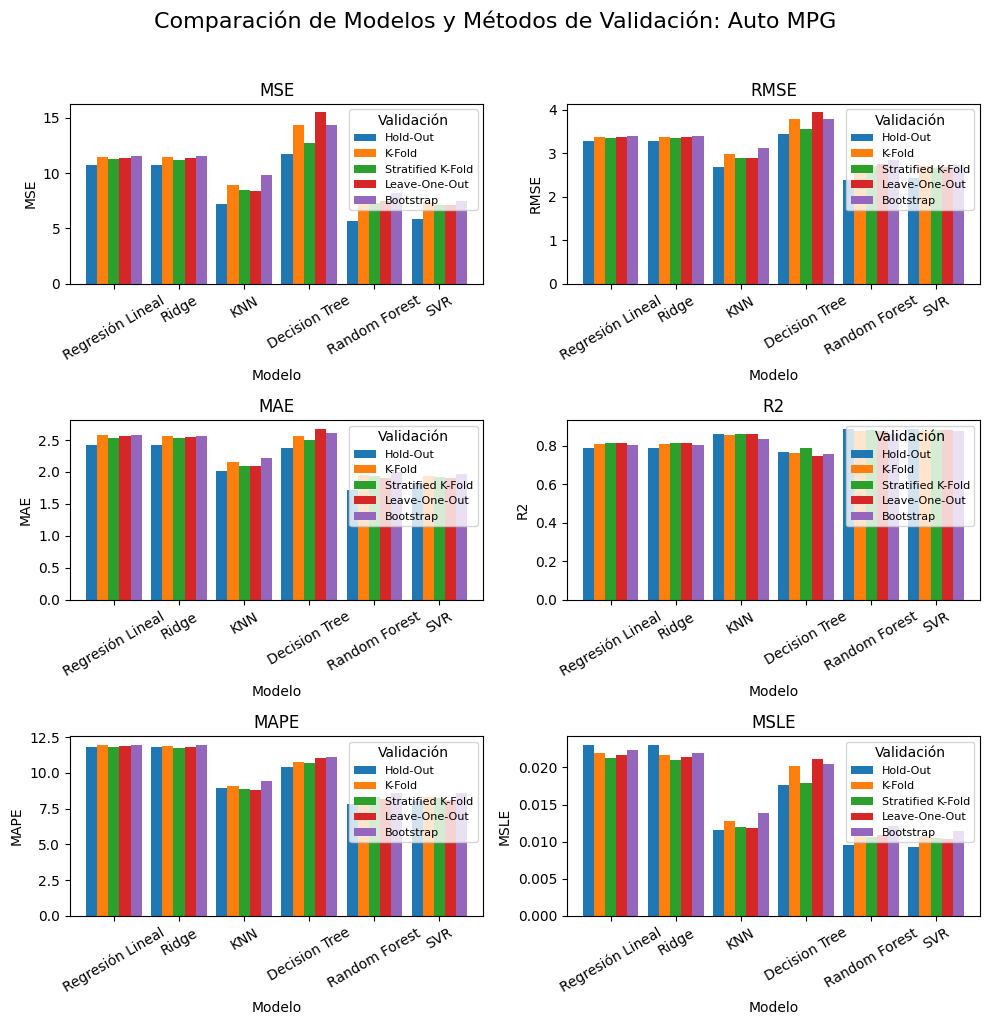

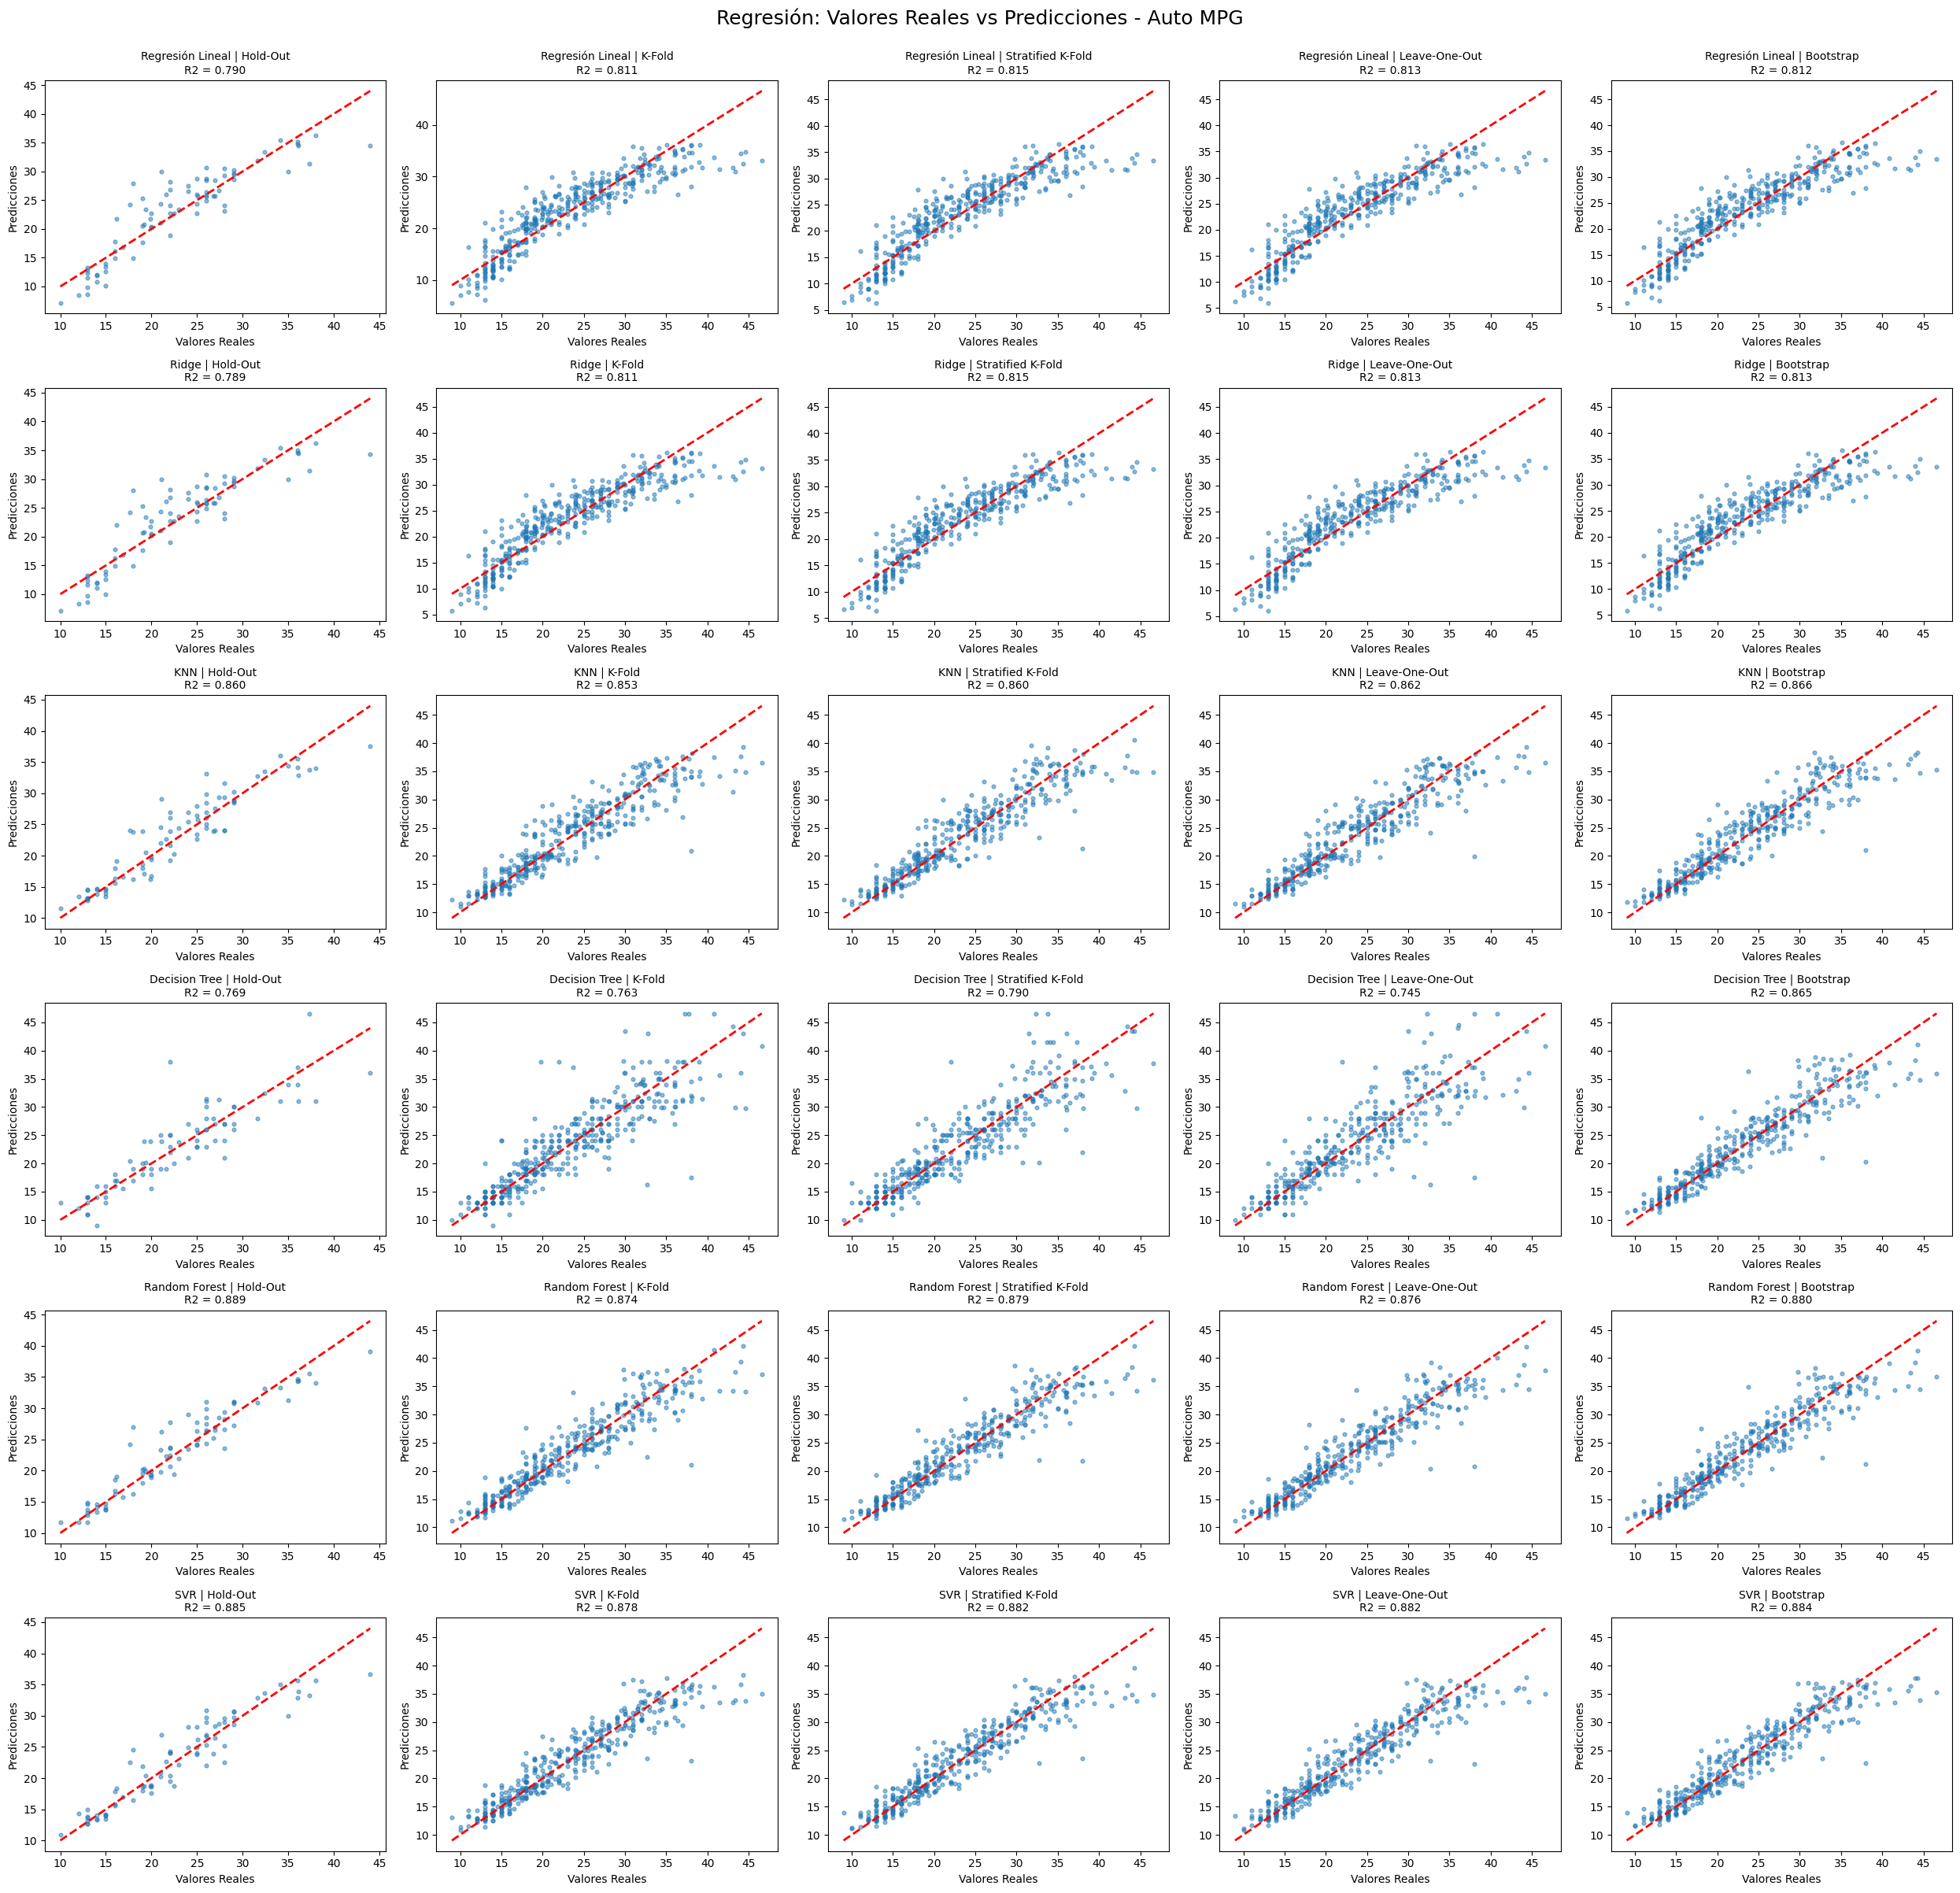

In [12]:
"""
Aplicar los modelos y metodos de validación a Auto MPG
"""

X, y = datasets["Auto MPG"]
resultados_auto, predicciones_auto = evaluar_validaciones(X, y, "Auto MPG", n_bootstrap=30)
display(resultados_auto)
graficar_comparacion(resultados_auto, "Auto MPG")
graficar_regresion(predicciones_auto, "Auto MPG")

#### Bike Sharing

Bike Sharing | Regresión Lineal | Hold-Out (0.0 s)
Bike Sharing | Regresión Lineal | K-Fold (0.0 s)
Bike Sharing | Regresión Lineal | Stratified K-Fold (0.1 s)
Bike Sharing | Regresión Lineal | Leave-One-Out (1.5 s)
Bike Sharing | Regresión Lineal | Bootstrap (0.1 s)
Bike Sharing | Ridge | Hold-Out (0.0 s)
Bike Sharing | Ridge | K-Fold (0.0 s)
Bike Sharing | Ridge | Stratified K-Fold (0.0 s)
Bike Sharing | Ridge | Leave-One-Out (1.5 s)
Bike Sharing | Ridge | Bootstrap (0.1 s)
Bike Sharing | KNN | Hold-Out (0.1 s)
Bike Sharing | KNN | K-Fold (2.1 s)
Bike Sharing | KNN | Stratified K-Fold (3.1 s)
Bike Sharing | KNN | Leave-One-Out (10.7 s)
Bike Sharing | KNN | Bootstrap (2.4 s)
Bike Sharing | Decision Tree | Hold-Out (0.1 s)
Bike Sharing | Decision Tree | K-Fold (0.3 s)
Bike Sharing | Decision Tree | Stratified K-Fold (0.3 s)
Bike Sharing | Decision Tree | Leave-One-Out (6.7 s)
Bike Sharing | Decision Tree | Bootstrap (0.6 s)
Bike Sharing | Random Forest | Hold-Out (0.5 s)
Bike Sharing |

,Dataset,Modelo,Validación,MSE,RMSE,MAE,R2,MAPE,MSLE
0,Bike Sharing,Regresión Lineal,Hold-Out,19379.828368,139.211452,104.803351,0.387981,347.709034,1.710995
1,Bike Sharing,Regresión Lineal,K-Fold,20135.765972,141.886755,106.014595,0.387573,335.050662,1.690342
2,Bike Sharing,Regresión Lineal,Stratified K-Fold,20127.119660,141.868957,106.003587,0.388226,335.225178,1.689674
3,Bike Sharing,Regresión Lineal,Leave-One-Out,20304.283265,142.493099,107.393802,0.341454,371.488409,1.829100
4,Bike Sharing,Regresión Lineal,Bootstrap,20177.897802,142.045064,106.143107,0.386039,336.279323,1.692368
5,Bike Sharing,Ridge,Hold-Out,19379.854022,139.211544,104.803108,0.387980,347.709519,1.710949
6,Bike Sharing,Ridge,K-Fold,20135.727289,141.886615,106.014213,0.387574,335.054603,1.690319
7,Bike Sharing,Ridge,Stratified K-Fold,20127.110205,141.868923,106.003310,0.388226,335.228889,1.689644
8,Bike Sharing,Ridge,Leave-One-Out,20285.849018,142.428400,107.357230,0.342052,370.550794,1.823314
9,Bike Sharing,Ridge,Bootstrap,20177.798867,142.044718,106.142660,0.386042,336.283348,1.692326


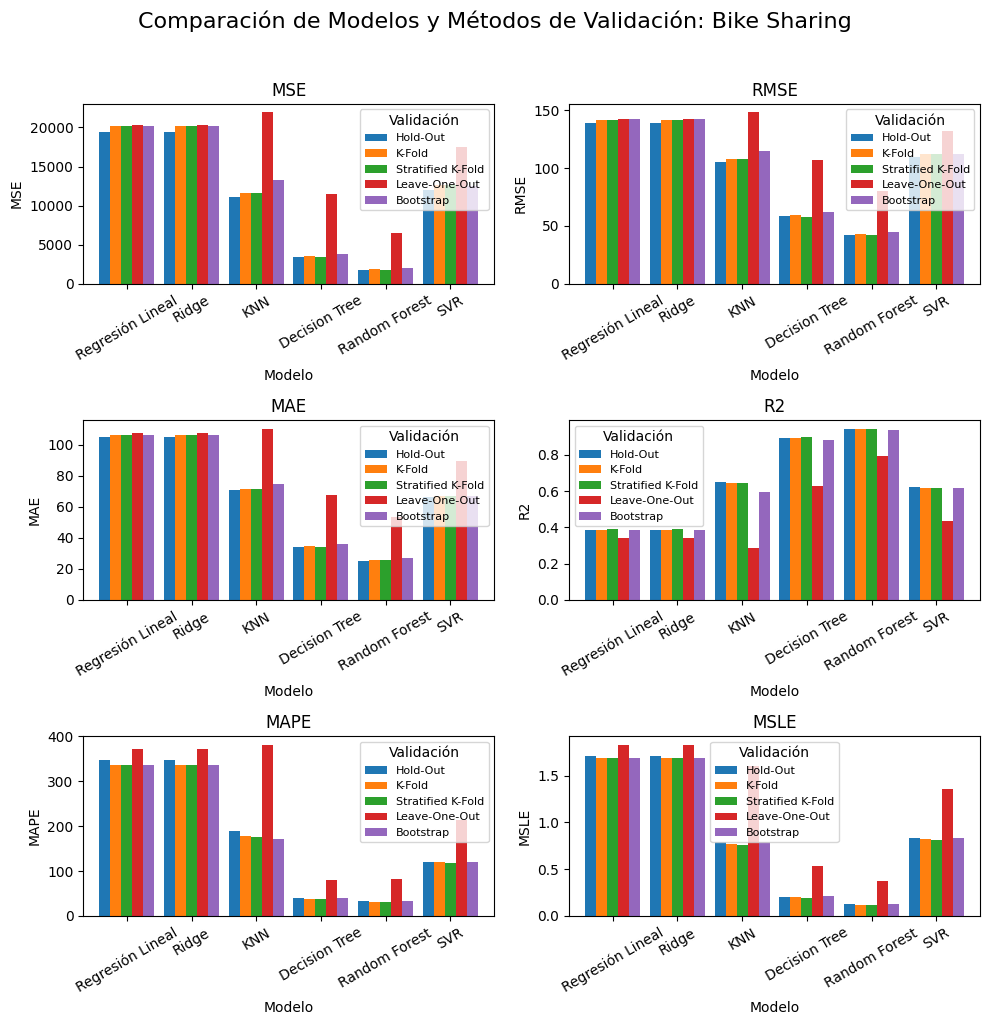

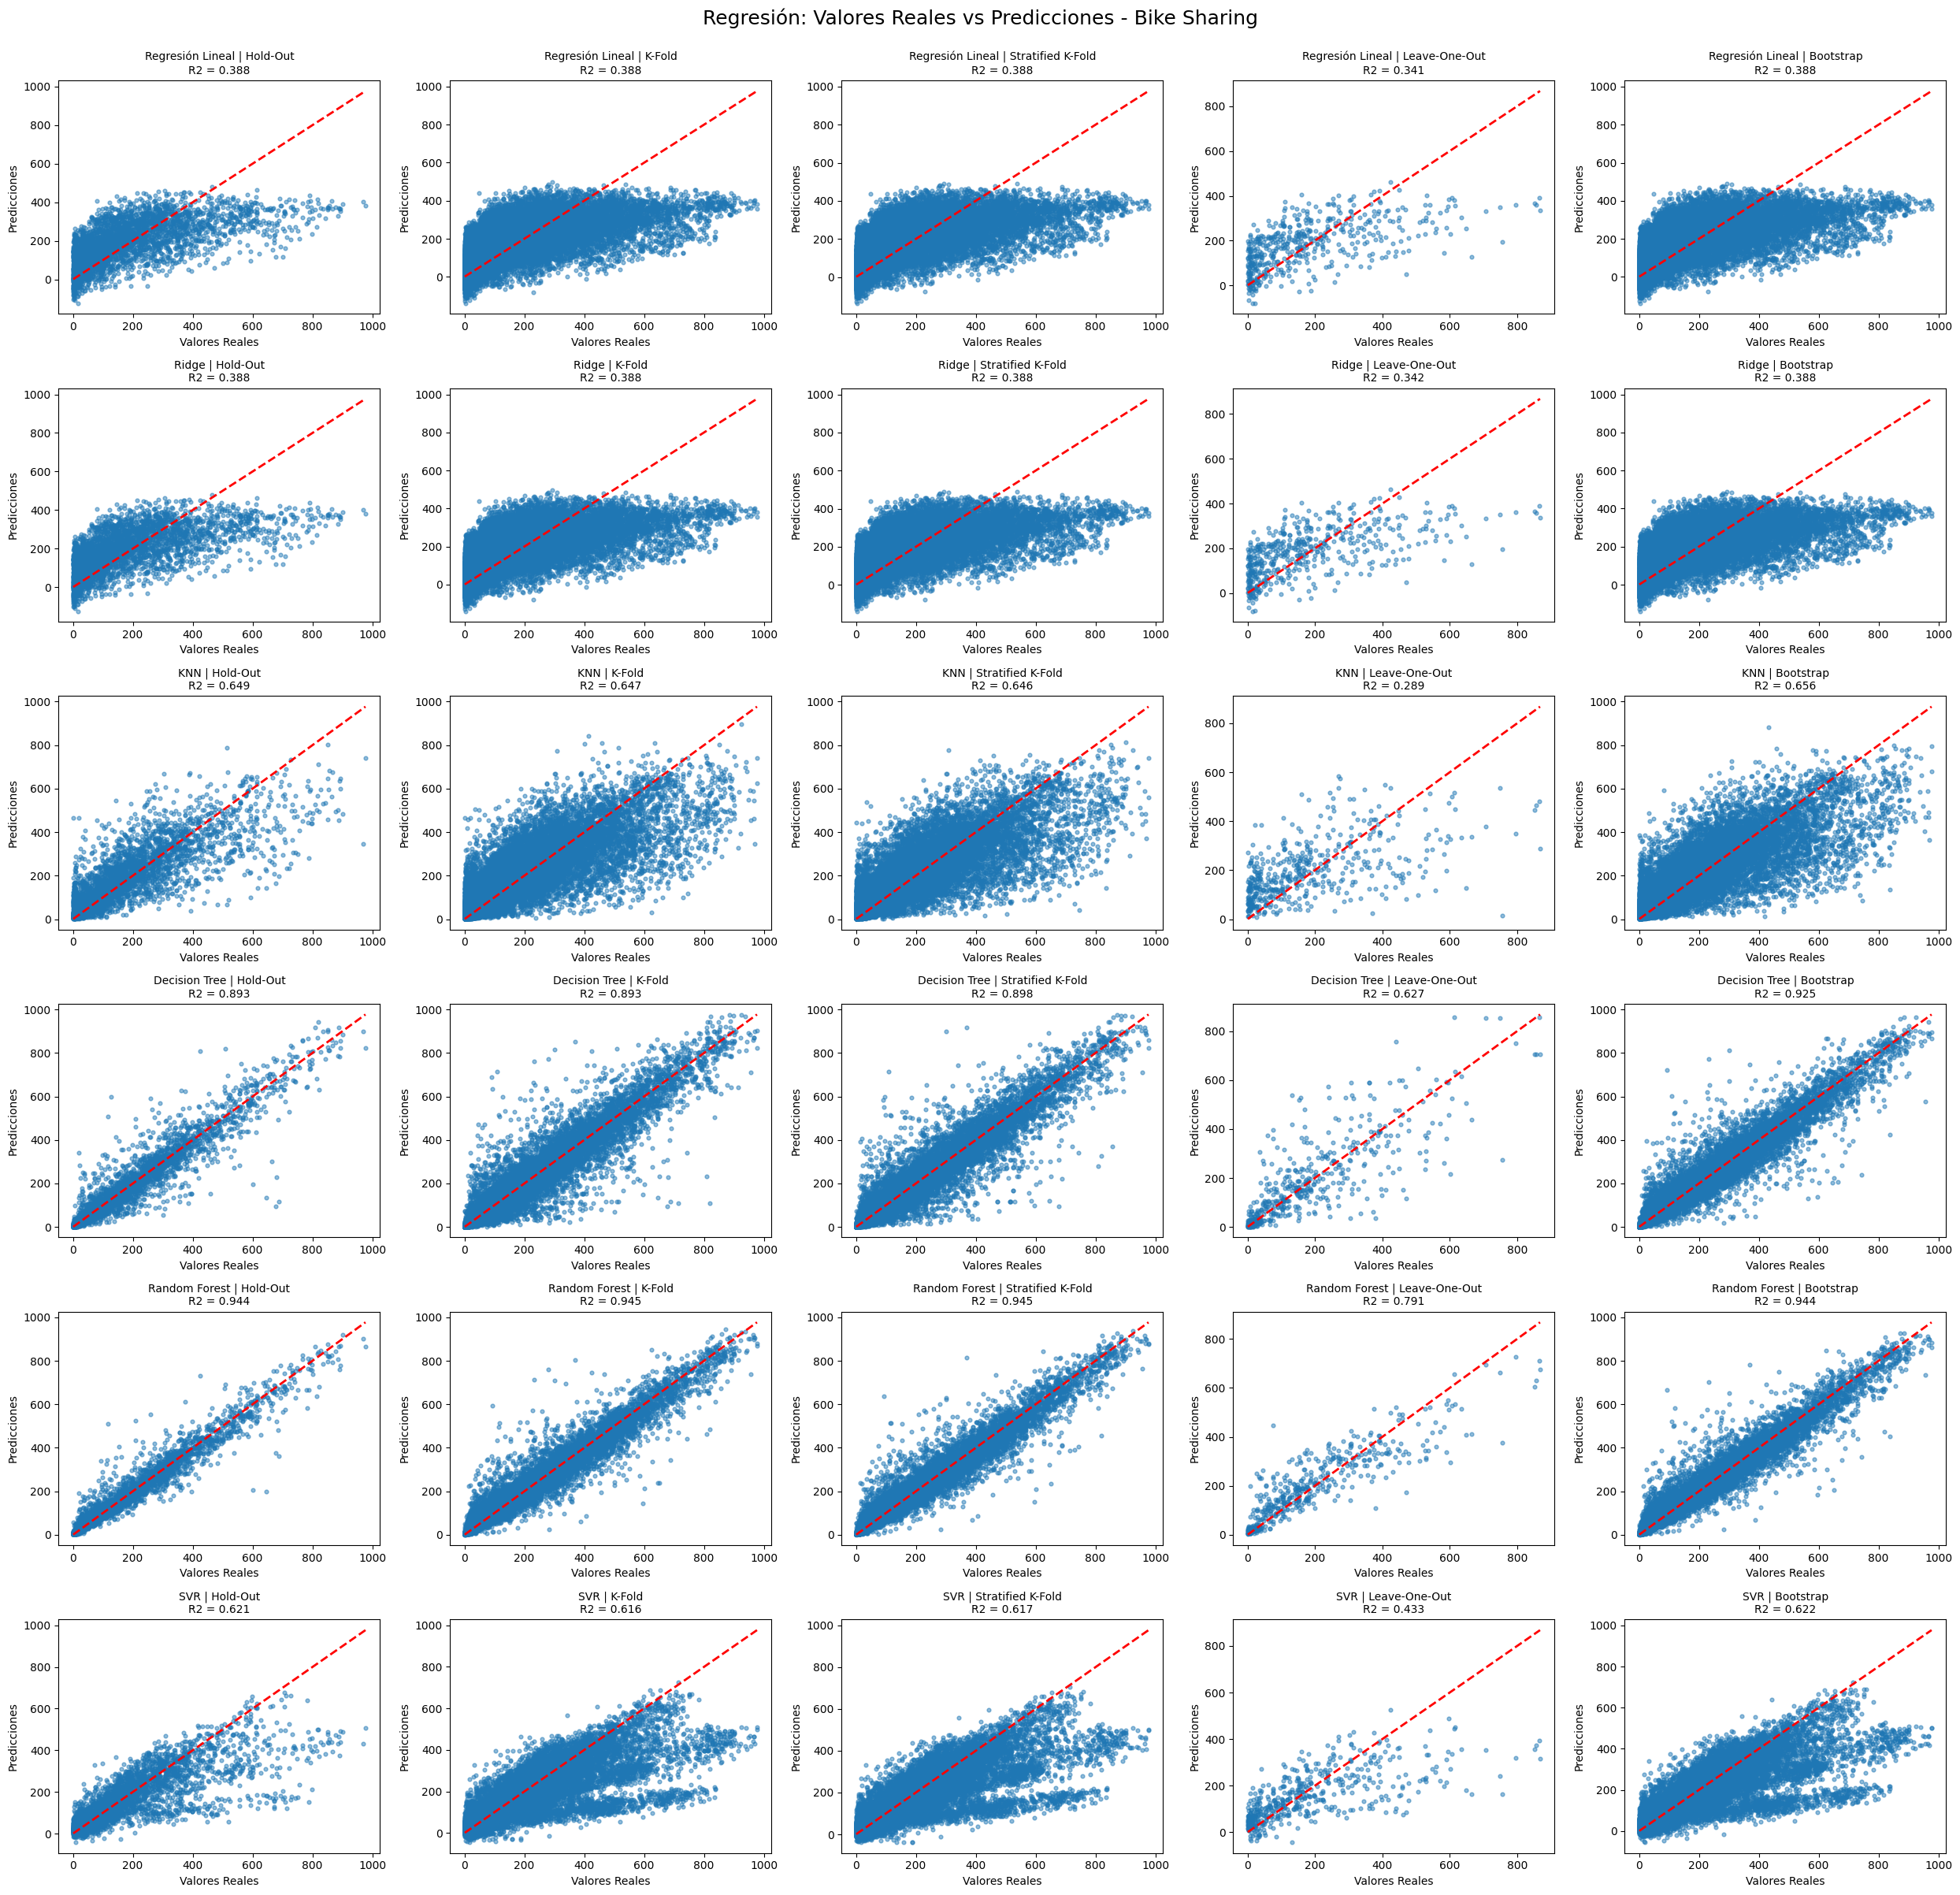

In [13]:
"""
Aplicar los modelos y metodos de validación a Bike Sharing (dataset grande: 10 iteraciones de Bootstrap)
"""

X, y = datasets["Bike Sharing"]
resultados_bike, predicciones_bike = evaluar_validaciones(X, y, "Bike Sharing", n_bootstrap=10)
display(resultados_bike)
graficar_comparacion(resultados_bike, "Bike Sharing")
graficar_regresion(predicciones_bike, "Bike Sharing")

#### Resumen

In [14]:
"""
Resumen: mejor modelo (menor RMSE) por dataset y metodo de validación
"""

resultados_totales = pd.concat(
    [resultados_california, resultados_diabetes, resultados_auto, resultados_bike],
    ignore_index=True
)

indices_mejores = resultados_totales.groupby(['Dataset', 'Validación'])['RMSE'].idxmin()
mejores_modelos = resultados_totales.loc[indices_mejores, ['Dataset', 'Validación', 'Modelo', 'RMSE', 'R2']]
display(mejores_modelos.reset_index(drop=True))

,Dataset,Validación,Modelo,RMSE,R2
0,Auto MPG,Bootstrap,SVR,2.727738,0.874089
1,Auto MPG,Hold-Out,Random Forest,2.378400,0.889171
2,Auto MPG,K-Fold,SVR,2.701415,0.878546
3,Auto MPG,Leave-One-Out,SVR,2.674083,0.882317
4,Auto MPG,Stratified K-Fold,SVR,2.668235,0.882498
5,Bike Sharing,Bootstrap,Random Forest,44.943294,0.938485
6,Bike Sharing,Hold-Out,Random Forest,42.069424,0.944108
7,Bike Sharing,K-Fold,Random Forest,42.561021,0.944841
8,Bike Sharing,Leave-One-Out,Random Forest,80.213546,0.791314
9,Bike Sharing,Stratified K-Fold,Random Forest,42.490954,0.945116
